# Lab 09: Build a Visual Monitoring Agent
**ITAI 1378 Computer Vision | Houston City College | AI and Robotics Program**
**Module 09: AI Agents for Computer Vision | Instructor: Patricia McManus**

> **Bonus lab (optional).** After Module 08, every lab in ITAI 1378 is a **bonus** lab. It is not mandatory, and skipping it will not lower your grade. Completing it earns bonus credit.

Welcome! In Module 09 you learned that an **AI agent** is a system that perceives its environment, reasons about what it sees, and takes an action, over and over. In this lab you will build a small **visual monitoring agent** for a workplace safety camera. A YOLO detector is the agent's eyes. Simple Python rules are its reasoning. Printed alerts and a log are its actions.

**What you will practice**
1. The Perception, Reasoning, Action (PRA) loop
2. Using an object detector as the agent's perception tool
3. Writing reasoning rules with a confidence threshold
4. Giving the agent short term **memory** so it does not repeat the same alert every frame
5. Zone aware reasoning (is the person inside a restricted area?)
6. A ReAct style log (plan, action, observation) and a human review guardrail

**Before you start:** File > Save a copy in Drive, then rename your copy `Lab_09_LastName_FirstName_ITAI1378.ipynb`. The free Colab CPU runtime is enough. No GPU is needed.

Look for cells marked **TODO**. Each one tells you exactly what to change. The notebook runs top to bottom even before you finish the TODOs, so you can always see where you are.

## Part 1: Setup
This cell installs **Ultralytics** (the YOLO library). It takes about a minute on a fresh runtime.

In [1]:
%pip install -q ultralytics opencv-python-headless

In [2]:
import os, time, urllib.request
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

# yolov8n is the small, fast "nano" detector from the lab preview slide.
model = YOLO("yolov8n.pt")
print("Model loaded. It knows", len(model.names), "COCO object classes.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Model loaded. It knows 80 COCO object classes.


## Part 2: The ideas in one screen
**The PRA loop** (the one Module 09 idea to remember):
1. **Perception:** gather information. Here, YOLO looks at a video frame and lists the objects it finds.
2. **Reasoning:** decide what to do. Here, Python rules such as "a person is inside the restricted zone".
3. **Action:** do something. Here, print an alert and write it to a log.

Then the loop repeats: perceive, reason, act, and look again. **Memory** ties the cycles together.

**ReAct** (Reason plus Act) is a common recipe for tool using agents: write a short plan, take an action (call a tool), read the observation, then revise. Logging these steps makes an agent much easier to debug.

**Rule of thumb from the slides:** use cheap, predictable tools first (like a detector). Use expensive reasoning, or a human, only when it is needed.

## Part 3: Get a video
We use two short public sample videos from Intel's open sample video collection: workers in a work area, and shoppers in a store aisle. If the download fails, you can upload any short `.mp4` with people in it using the folder icon on the left, then set `VIDEO_PATH` to its file name.

FPS: 59.9 | frames: 4548 | length: 76 seconds | size: 1920x1080


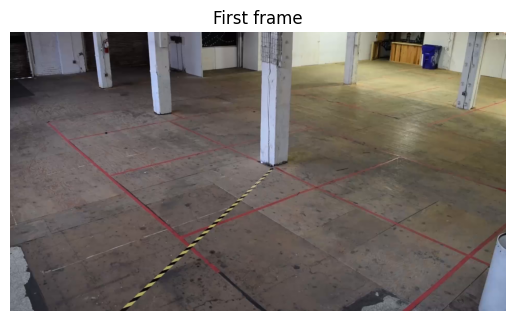

In [3]:
VIDEOS = {
    "workers": "https://github.com/intel-iot-devkit/sample-videos/raw/master/worker-zone-detection.mp4",
    "store":   "https://github.com/intel-iot-devkit/sample-videos/raw/master/store-aisle-detection.mp4",
}

def download(name):
    path = name + ".mp4"
    if not os.path.exists(path):
        print("Downloading", name, "video ...")
        urllib.request.urlretrieve(VIDEOS[name], path)
    return path

VIDEO_PATH = download("workers")
STORE_PATH = download("store")      # used in Part 7

cap = cv2.VideoCapture(VIDEO_PATH)
FPS = cap.get(cv2.CAP_PROP_FPS)
N_FRAMES = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
ok, first_frame = cap.read()
cap.release()
print(f"FPS: {FPS:.1f} | frames: {N_FRAMES} | length: {N_FRAMES / FPS:.0f} seconds | size: {first_frame.shape[1]}x{first_frame.shape[0]}")
plt.imshow(cv2.cvtColor(first_frame, cv2.COLOR_BGR2RGB)); plt.title("First frame"); plt.axis("off"); plt.show()

## Part 4: The agent, one piece at a time
We split the agent into three small functions so each part of the PRA loop is easy to see.

**Perception** turns a frame into a list of detections. Each detection is a small dictionary with a label, a confidence score, and a box.

In [4]:
def perceive(frame, conf=0.25):
    """PERCEPTION: run YOLO on one frame and return a simple list of detections."""
    result = model(frame, conf=conf, verbose=False)[0]
    detections = []
    for box in result.boxes:
        x1, y1, x2, y2 = [float(v) for v in box.xyxy[0]]
        detections.append({
            "label": model.names[int(box.cls[0])],
            "conf": float(box.conf[0]),
            "box": (x1, y1, x2, y2),
        })
    return detections, result

dets, _ = perceive(first_frame)
for d in dets:
    print(f"{d['label']:>10}  conf {d['conf']:.2f}")

### TODO 1: Look up a class by name
COCO class numbers are easy to get wrong ("person" is 0, but what is "car"?). Instead of memorizing numbers, the agent should look up names in `model.names`, which is a dictionary like `{0: 'person', 1: 'bicycle', 2: 'car', ...}`.

Finish `class_id_for(name)` so it returns the number for a class name. For example `class_id_for("car")` should return `2`.

In [5]:
def class_id_for(name):
    # TODO 1 complete: look through the COCO class names instead of guessing IDs.
    for class_id, class_name in model.names.items():
        if class_name == name:
            return class_id
    return None

for test_name in ["person", "car", "dog", "cup"]:
    print(f"{test_name:>7} -> {class_id_for(test_name)}")

assert class_id_for("person") == 0
assert class_id_for("car") == 2
assert class_id_for("not_a_coco_class") is None
print("Class lookup tests passed.")

 person -> 0
    car -> 2
    dog -> 16
    cup -> 41
Class lookup tests passed.


**Reasoning** looks at the detections and decides whether something worth reporting is happening. Our first rule: *alert if at least `min_count` objects of the target class are seen with confidence at or above `min_conf`.*

### TODO 2: Use the confidence threshold
Right now the rule counts every detection of the target, even very unsure ones. Change it so it only counts detections whose `conf` is at least `min_conf`.

In [6]:
def reason(detections, target="person", min_conf=0.5, min_count=1):
    """REASONING: return (should_alert, matching_detections)."""
    # TODO 2 complete: count only the right class at or above the confidence threshold.
    matches = [d for d in detections if d["label"] == target and d["conf"] >= min_conf]
    return len(matches) >= min_count, matches

def act(frame_number, matches, target, log, fps=FPS):
    """ACTION: print an alert and write it to the log."""
    seconds = frame_number / fps
    message = f"[{seconds:6.1f}s] ALERT: {len(matches)} {target}(s) seen"
    print(message)
    log.append({"frame": frame_number, "time_s": round(seconds, 1), "count": len(matches), "message": message})

# Confirm that a weak detection does not trigger an alert.
sample_detections = [
    {"label": "person", "conf": 0.42, "box": (0, 0, 10, 10)},
    {"label": "person", "conf": 0.81, "box": (0, 0, 10, 10)},
    {"label": "car", "conf": 0.95, "box": (0, 0, 10, 10)},
]
assert len(reason(sample_detections, min_conf=0.5)[1]) == 1
assert reason(sample_detections, min_conf=0.85)[0] is False
print("Confidence threshold tests passed.")

Confidence threshold tests passed.


### Run the basic agent
The loop below checks one frame every `every_n` frames (every 15th frame of a 60 FPS video is 4 checks per second). It shows up to three annotated frames so the notebook stays readable.

[   3.0s] ALERT: 1 person(s) seen


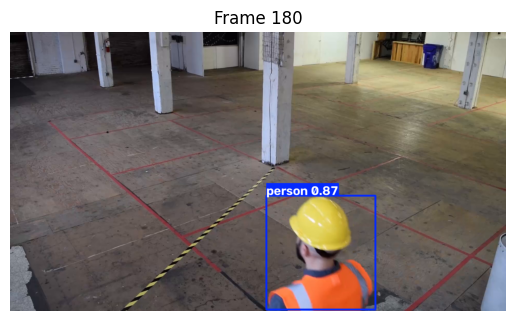

[   3.3s] ALERT: 1 person(s) seen


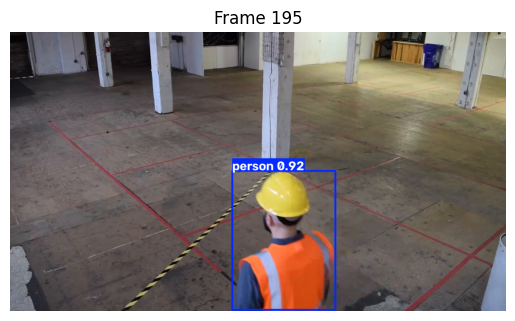

[   3.5s] ALERT: 1 person(s) seen


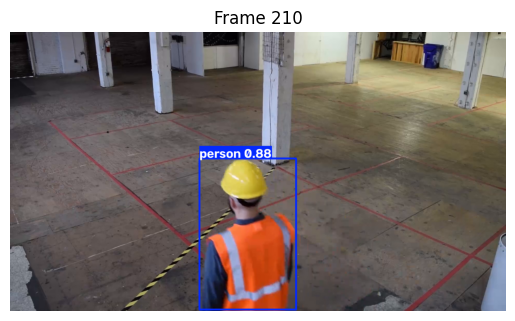

[   3.8s] ALERT: 1 person(s) seen
[   4.0s] ALERT: 1 person(s) seen
[   4.3s] ALERT: 1 person(s) seen
[   4.5s] ALERT: 1 person(s) seen
[   4.8s] ALERT: 1 person(s) seen
[   5.0s] ALERT: 1 person(s) seen
[   5.3s] ALERT: 1 person(s) seen
[   5.5s] ALERT: 1 person(s) seen
[   5.8s] ALERT: 1 person(s) seen
[   6.0s] ALERT: 1 person(s) seen
[   6.3s] ALERT: 1 person(s) seen
[   6.5s] ALERT: 1 person(s) seen
[   6.8s] ALERT: 1 person(s) seen
[   7.0s] ALERT: 1 person(s) seen
[   7.3s] ALERT: 1 person(s) seen
[   7.5s] ALERT: 1 person(s) seen
[   7.8s] ALERT: 1 person(s) seen
[   8.0s] ALERT: 1 person(s) seen
[   8.3s] ALERT: 1 person(s) seen
[   8.5s] ALERT: 1 person(s) seen
[   8.8s] ALERT: 1 person(s) seen
[   9.0s] ALERT: 1 person(s) seen
[   9.3s] ALERT: 1 person(s) seen
[   9.5s] ALERT: 1 person(s) seen
[  12.5s] ALERT: 1 person(s) seen
[  12.8s] ALERT: 1 person(s) seen
[  13.0s] ALERT: 1 person(s) seen
[  13.3s] ALERT: 1 person(s) seen
[  13.5s] ALERT: 1 person(s) seen
[  13.8s] ALER

In [7]:
def run_agent(video_path, target="person", every_n=15, max_seconds=40, min_conf=0.5,
              reason_fn=None, show=3):
    reason_fn = reason_fn or (lambda dets: reason(dets, target=target, min_conf=min_conf))
    cap = cv2.VideoCapture(video_path)
    fps = cap.get(cv2.CAP_PROP_FPS)
    log, frame_number, shown = [], 0, 0
    start = time.time()
    while cap.isOpened() and frame_number < max_seconds * fps:
        ok, frame = cap.read()
        if not ok:
            break
        frame_number += 1
        if frame_number % every_n != 0:
            continue
        detections, result = perceive(frame)          # PERCEPTION
        should_alert, matches = reason_fn(detections)  # REASONING
        if should_alert:                               # ACTION
            act(frame_number, matches, target, log)
            if shown < show:
                plt.imshow(cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB))
                plt.title(f"Frame {frame_number}"); plt.axis("off"); plt.show()
                shown += 1
    cap.release()
    print(f"\nChecked about {frame_number // every_n} frames in {time.time() - start:.0f} s. Alerts: {len(log)}")
    return log

basic_log = run_agent(VIDEO_PATH, target="person", max_seconds=20)

**Reflection 1:** In your own words, what are the three parts of the PRA loop, and which function in this notebook does each one? How many alerts did the basic agent raise in 20 seconds? Would a safety manager want that many messages?

*Your answer:*

  - The PRA loop has three parts: perception, reasoning, and action. First, `perceive()` uses YOLO to find objects in a video frame. Next, `reason()` checks those detections and decides whether they meet the rule. Then `act()` prints an alert and saves it in the log. The `run_agent()` function repeats those steps as the video plays. I used the workers video for a 20-second test, and the basic agent raised 57 alerts. A safety manager probably wouldn't want that many repeated messages whenever the same person remains in view. That would get distracting, and important warnings might become harder to notice. The agent needs a way to avoid repeating the same event.

## Part 5: Give the agent memory
The basic agent shouts "ALERT" on almost every frame while the same people stand in view. Real monitoring agents use **short term memory** ("Did I already send this alert?") so they report **events**, not frames.

### TODO 3: Add a cooldown
Finish `reason_with_memory` so the agent only alerts if at least `cooldown_s` seconds have passed since its last alert. The memory is a small dictionary that survives between loop cycles.

In [8]:
def make_memory_reasoner(target="person", min_conf=0.5, cooldown_s=5.0, every_n=15, fps=None):
    memory = {"last_alert_time": None, "checks": 0}
    video_fps = FPS if fps is None else fps

    def reason_with_memory(detections):
        memory["checks"] += 1
        now = memory["checks"] * every_n / video_fps  # video time in seconds
        should_alert, matches = reason(detections, target=target, min_conf=min_conf)
        if not should_alert:
            return False, matches
        # TODO 3 complete: skip an alert when it falls inside the cooldown period.
        if memory["last_alert_time"] is not None and now - memory["last_alert_time"] < cooldown_s:
            return False, matches
        memory["last_alert_time"] = now
        return True, matches

    return reason_with_memory

# A small independent test proves the cooldown changes the decision.
_test_memory = make_memory_reasoner(cooldown_s=5, every_n=15, fps=30)
_test_detection = [{"label": "person", "conf": 0.8, "box": (0, 0, 5, 5)}]
assert _test_memory(_test_detection)[0] is True
assert _test_memory(_test_detection)[0] is False
print("Cooldown test passed.")

memory_log = run_agent(VIDEO_PATH, target="person", max_seconds=20, show=0,
                       reason_fn=make_memory_reasoner(cooldown_s=5.0))
print(f"Basic agent alerts: {len(basic_log)} | Agent with memory: {len(memory_log)}")

Cooldown test passed.
[   3.0s] ALERT: 1 person(s) seen
[   8.0s] ALERT: 1 person(s) seen
[  13.0s] ALERT: 1 person(s) seen
[  18.0s] ALERT: 1 person(s) seen

Checked about 79 frames in 19 s. Alerts: 4
Basic agent alerts: 57 | Agent with memory: 4


**Reflection 2:** How many alerts did the agent with memory raise compared with the basic agent? What could go wrong if the cooldown were very long, for example 10 minutes? The slides warn about storing identity or face data in long term memory. Why is that a privacy concern?

*Your answer:*

  - After adding memory, my agent raised only 4 alerts compared to 57 alerts from the basic agent. The cooldown made a big difference because the agent stopped sending repeated warnings about the same person every few seconds. I think this makes the system more useful because a safety manager would not have to deal with so many unnecessary notifications. However, if the cooldown lasted 10 minutes, the agent might miss a new incident during that time. Another concern involves privacy. If the system stored people's faces or identities for a long time, someone could use that information to track workers without their permission. I think the agent should only keep the information it needs to detect safety risks.

## Part 6: Zone aware reasoning
A detector says "person". A safety rule says "a person **inside the restricted zone**". The zone below is a rectangle given as `(x1, y1, x2, y2)` in pixels. We use the **bottom center** of each box (where the person's feet are) to decide if they are inside.

### TODO 4: Write the zone test
Finish `in_zone` so it returns `True` when the point `(px, py)` is inside the rectangle.

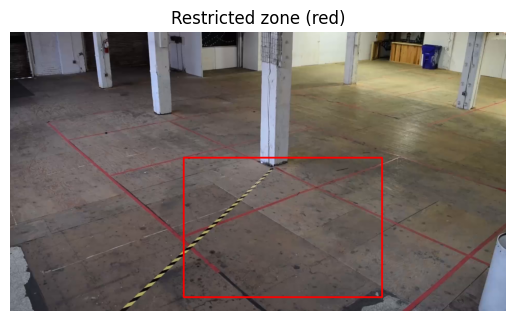

Quick test, zone center is inside: True
[   5.0s] ALERT: 1 person(s) seen


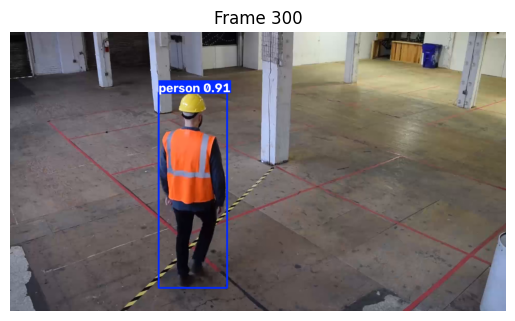

[   5.3s] ALERT: 1 person(s) seen


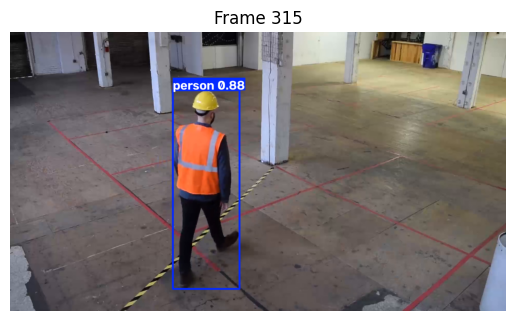

[   5.5s] ALERT: 1 person(s) seen
[   5.8s] ALERT: 1 person(s) seen
[   6.0s] ALERT: 1 person(s) seen
[   6.3s] ALERT: 1 person(s) seen
[   6.5s] ALERT: 1 person(s) seen
[   6.8s] ALERT: 1 person(s) seen
[   7.0s] ALERT: 1 person(s) seen
[   7.3s] ALERT: 1 person(s) seen
[   7.5s] ALERT: 1 person(s) seen
[   7.8s] ALERT: 1 person(s) seen
[  26.5s] ALERT: 1 person(s) seen
[  26.8s] ALERT: 1 person(s) seen
[  27.0s] ALERT: 1 person(s) seen
[  27.3s] ALERT: 1 person(s) seen
[  27.5s] ALERT: 1 person(s) seen
[  27.8s] ALERT: 1 person(s) seen
[  28.0s] ALERT: 1 person(s) seen
[  28.3s] ALERT: 1 person(s) seen
[  28.5s] ALERT: 1 person(s) seen
[  28.8s] ALERT: 1 person(s) seen
[  36.3s] ALERT: 1 person(s) seen
[  36.5s] ALERT: 1 person(s) seen
[  36.8s] ALERT: 1 person(s) seen
[  37.0s] ALERT: 1 person(s) seen
[  37.3s] ALERT: 1 person(s) seen
[  37.5s] ALERT: 1 person(s) seen
[  37.8s] ALERT: 1 person(s) seen
[  38.0s] ALERT: 1 person(s) seen
[  38.3s] ALERT: 1 person(s) seen
[  38.5s] ALER

In [9]:
H, W = first_frame.shape[:2]
ZONE = (int(W * 0.35), int(H * 0.45), int(W * 0.75), int(H * 0.95))

def in_zone(px, py, zone=ZONE):
    x1, y1, x2, y2 = zone
    # TODO 4 complete: include the rectangle's edges in the zone check.
    return x1 <= px <= x2 and y1 <= py <= y2

def zone_reason(detections, target="person", min_conf=0.5):
    should_alert, matches = reason(detections, target=target, min_conf=min_conf)
    inside = [d for d in matches if in_zone((d["box"][0] + d["box"][2]) / 2, d["box"][3])]
    return len(inside) > 0, inside

preview = first_frame.copy()
cv2.rectangle(preview, ZONE[:2], ZONE[2:], (0, 0, 255), 6)
plt.imshow(cv2.cvtColor(preview, cv2.COLOR_BGR2RGB)); plt.title("Restricted zone (red)"); plt.axis("off"); plt.show()
print("Quick test, zone center is inside:", in_zone((ZONE[0] + ZONE[2]) / 2, (ZONE[1] + ZONE[3]) / 2))
assert in_zone((ZONE[0] + ZONE[2]) / 2, (ZONE[1] + ZONE[3]) / 2)
assert not in_zone(ZONE[0] - 1, ZONE[1] - 1)

zone_log = run_agent(VIDEO_PATH, target="person", max_seconds=40, show=2, reason_fn=zone_reason)

**Reflection 3:** How did the number of alerts change when the rule cared about the zone? Describe one more reasoning rule you could add (for example a time rule, a count rule, or "person near a forklift"). What extra perception would that rule need?

*Your answer:*

  - After adding the restricted zone rule, my agent raised 37 alerts, compared to 57 alerts from the basic agent. However, the zone test checked 40 seconds of video, while the basic test checked only 20 seconds, so the results are not a direct comparison. The zone rule made the alerts more specific because the agent focused on people inside a particular area instead of reporting everyone it detected. I think this makes the system more useful for workplace safety. One additional rule I would add is detecting when someone gets too close to moving equipment. The agent would need to recognize both people and equipment, track their positions, and estimate the distance between them. This could help identify dangerous situations before an accident happens.

## Part 7: A ReAct style log and a human review guardrail
Detectors are sometimes unsure. A responsible agent does not act alone on weak evidence. It **escalates** uncertain cases to a person. Below, each check writes a short **plan, action, observation** entry, like the ReAct pattern from the slides. We run it on the **store** video, where shoppers are often partly hidden by shelves, so the detector is sometimes unsure.

### TODO 5: Add the escalation rule
In `decide`, return `"HUMAN_REVIEW"` when the best confidence for the target is between `low` and `high` (unsure), `"ALERT"` when it is at or above `high`, and `"IGNORE"` otherwise.

In [12]:
def decide(best_conf, low=0.3, high=0.6):
    # TODO 5 complete: raise a confident alert, request human review, or ignore.
    if best_conf >= high:
        return "ALERT"
    elif best_conf >= low:
        return "HUMAN_REVIEW"
    return "IGNORE"

def react_agent(video_path, target="person", every_n=30, max_seconds=30):
    cap = cv2.VideoCapture(video_path)
    video_fps = cap.get(cv2.CAP_PROP_FPS)
    if video_fps <= 0:
        cap.release()
        raise ValueError("Could not read the store video's FPS")
    trace, frame_number = [], 0
    while cap.isOpened() and frame_number < max_seconds * video_fps:
        ok, frame = cap.read()
        if not ok:
            break
        frame_number += 1
        if frame_number % every_n:
            continue
        plan = f"Check frame {frame_number} for {target} with the detector (cheap tool first)."
        detections, _ = perceive(frame, conf=0.1)  # Keep uncertain detections for review.
        for d in [d for d in detections if d["label"] == target]:
            decision = decide(d["conf"])
            trace.append({
                "time_s": round(frame_number / video_fps, 1),
                "plan": plan,
                "action": "Use YOLO detection, then apply the confidence guardrail",
                "observation": f"{target} candidate, confidence {d['conf']:.2f}",
                "decision": decision,
            })
    cap.release()
    return trace

print("Quick test:", decide(0.9), decide(0.45), decide(0.1), "(expected ALERT HUMAN_REVIEW IGNORE)\n")
assert [decide(x) for x in [0.9, 0.45, 0.1]] == ["ALERT", "HUMAN_REVIEW", "IGNORE"]
trace = react_agent(STORE_PATH)
for step in trace[:15]:
    print(f"{step['time_s']:5.1f}s | {step['observation']:<36} | {step['decision']}")
print("...")
print("\nDecisions:", {d: sum(s["decision"] == d for s in trace) for d in ["ALERT", "HUMAN_REVIEW", "IGNORE"]})
for step in [s for s in trace if s["decision"] == "HUMAN_REVIEW"][:5]:
    print("Sent to a human:", step["time_s"], "s |", step["observation"]);

Quick test: ALERT HUMAN_REVIEW IGNORE (expected ALERT HUMAN_REVIEW IGNORE)

  7.5s | person candidate, confidence 0.14    | IGNORE
  7.5s | person candidate, confidence 0.12    | IGNORE
  9.0s | person candidate, confidence 0.86    | ALERT
  9.5s | person candidate, confidence 0.88    | ALERT
 10.0s | person candidate, confidence 0.88    | ALERT
 10.5s | person candidate, confidence 0.88    | ALERT
 11.0s | person candidate, confidence 0.90    | ALERT
 11.5s | person candidate, confidence 0.87    | ALERT
 11.5s | person candidate, confidence 0.56    | HUMAN_REVIEW
 12.0s | person candidate, confidence 0.92    | ALERT
 12.0s | person candidate, confidence 0.77    | ALERT
 12.5s | person candidate, confidence 0.91    | ALERT
 12.5s | person candidate, confidence 0.90    | ALERT
 13.0s | person candidate, confidence 0.91    | ALERT
 13.0s | person candidate, confidence 0.89    | ALERT
...

Decisions: {'ALERT': 106, 'HUMAN_REVIEW': 8, 'IGNORE': 7}
Sent to a human: 11.5 s | person candidate

### TODO 6: Monitor a different object
Pick another COCO object and run the agent on the **store** video, where you will find objects such as `bowl`, `cup`, `refrigerator`, and `person`. You may also upload your own short clip.
1. Set `MY_TARGET` to your object name and make sure `class_id_for(MY_TARGET)` is not `None`.
2. Run the cell and look at the alerts.

In [13]:
MY_TARGET = "cup"   # TODO 6 complete: a different COCO class from "person".
print("Class id:", class_id_for(MY_TARGET))
assert MY_TARGET != "person" and class_id_for(MY_TARGET) is not None

# The store clip may use a different FPS than the workers clip.
_store_cap = cv2.VideoCapture(STORE_PATH)
STORE_FPS = _store_cap.get(cv2.CAP_PROP_FPS)
_store_cap.release()

my_log = run_agent(STORE_PATH, target=MY_TARGET, every_n=30, max_seconds=30, show=2, min_conf=0.4,
                   reason_fn=make_memory_reasoner(target=MY_TARGET, min_conf=0.4,
                                                   cooldown_s=3.0, every_n=30, fps=STORE_FPS))
print(f"New object: {MY_TARGET} | Alerts: {len(my_log)}")

Class id: 41

Checked about 59 frames in 10 s. Alerts: 0
New object: cup | Alerts: 0


**Reflection 4:** Which object did you choose, and how well did the agent find it? Name one challenge this agent would face in a real workplace (lighting, camera angle, people hidden behind equipment, unusual clothing) and how you might handle it.

*Your answer:*

  - I chose a cup as my second object because I wanted to see how the agent would handle something smaller than a person. The model recognized cup as a valid COCO class, but it didn't raise any alerts during the store video. This could mean that the cups were too small, difficult to see, or didn't meet the confidence threshold. This showed me that choosing a valid object class doesn't guarantee the agent will detect it in every video. One challenge in a real workplace would be objects hiding behind shelves or equipment. The camera might miss important details if something blocks its view. To improve this, I would try different camera angles and adjust the confidence threshold carefully to avoid missing objects or creating too many false alerts.

## Part 8: Wrap-up questions
Answer each in about 75 to 150 words, in your own words.

1. **Agent or not?** The slides say agents are not always the right tool. Describe one camera task where a plain detector plus a counter is enough, and one where an agent loop with memory and tools really helps.

  - I think a simple detector and counter would work well for counting how many people enter a store. The system only needs to recognize people and update a number, so adding a more complicated agent would not make much sense. However, monitoring a dangerous workplace would require more than just counting objects. An agent could recognize people, check whether they enter restricted areas, remember previous alerts, and decide when to notify someone. In this lab, adding memory reduced the number of alerts from 57 to just 4, which showed me how useful even a simple improvement can be. I learned that not every computer vision task needs an AI agent. Sometimes a basic program can do the job without adding unnecessary complexity.


2. **Your own application:** Describe a real visual monitoring agent you would like to build. What would it perceive, what reasoning rules would it use, what actions would it take, and when would it ask a human?

  - I would like to build a visual monitoring agent for a robotics lab where students work near moving robots and equipment. The agent would use cameras to recognize people and monitor areas where robots are operating. It would check whether someone gets too close to a moving robot or enters a restricted area. If the agent noticed a possible danger, it could send a warning or activate a sound alert. I would add memory so it wouldn't repeat the same warning every few seconds. I would also want the agent to recognize whether a robot is moving or standing still before making a decision. If the system couldn't clearly understand the situation or had low confidence, it would ask the instructor to review it.


3. **Guardrails:** A CV agent affects people. Name two guardrails you would put in place before deploying your agent (think privacy, false alarms, and who reviews decisions).

*Your answers:*

  - Before using my monitoring agent in a real workplace, I would focus on two important guardrails: privacy protection and human review. First, I would avoid collecting unnecessary personal information, especially people's faces or identities. The agent should focus on detecting safety risks rather than tracking individual workers. I would only keep the information necessary for safety alerts and limit who could access it. Second, I would make sure a human reviews uncertain situations before the system takes any serious action. Computer vision models can make mistakes because of poor lighting, camera angles, or objects blocking their view. I wouldn't want someone to face consequences because the agent misunderstood what happened. These guardrails would help make the system safer and more reliable.

---
**Submit:** Runtime > Restart session and run all. Then File > Download > Download .ipynb and upload `Lab_09_LastName_FirstName_ITAI1378.ipynb` to the Lab 09 (Bonus) assignment in Canvas. Make sure your outputs are visible.

If you used an AI assistant to help with an error or a concept, add one sentence at the end saying what you used it for.

**AI Usage Note:** I used ChatGPT to help me understand and troubleshoot Python code errors while completing this lab.